In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, PrecisionRecallDisplay, f1_score
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                8000 non-null   int64  
 1   Gender             8000 non-null   object 
 2   Income             8000 non-null   int64  
 3   CampaignChannel    8000 non-null   object 
 4   CampaignType       8000 non-null   object 
 5   AdSpend            8000 non-null   float64
 6   ClickThroughRate   8000 non-null   float64
 7   ConversionRate     8000 non-null   float64
 8   WebsiteVisits      8000 non-null   int64  
 9   PagesPerVisit      8000 non-null   float64
 10  TimeOnSite         8000 non-null   float64
 11  SocialShares       8000 non-null   int64  
 12  EmailOpens         8000 non-null   int64  
 13  EmailClicks        8000 non-null   int64  
 14  PreviousPurchases  8000 non-null   int64  
 15  LoyaltyPoints      8000 non-null   int64  
 16  Conversion         8000 

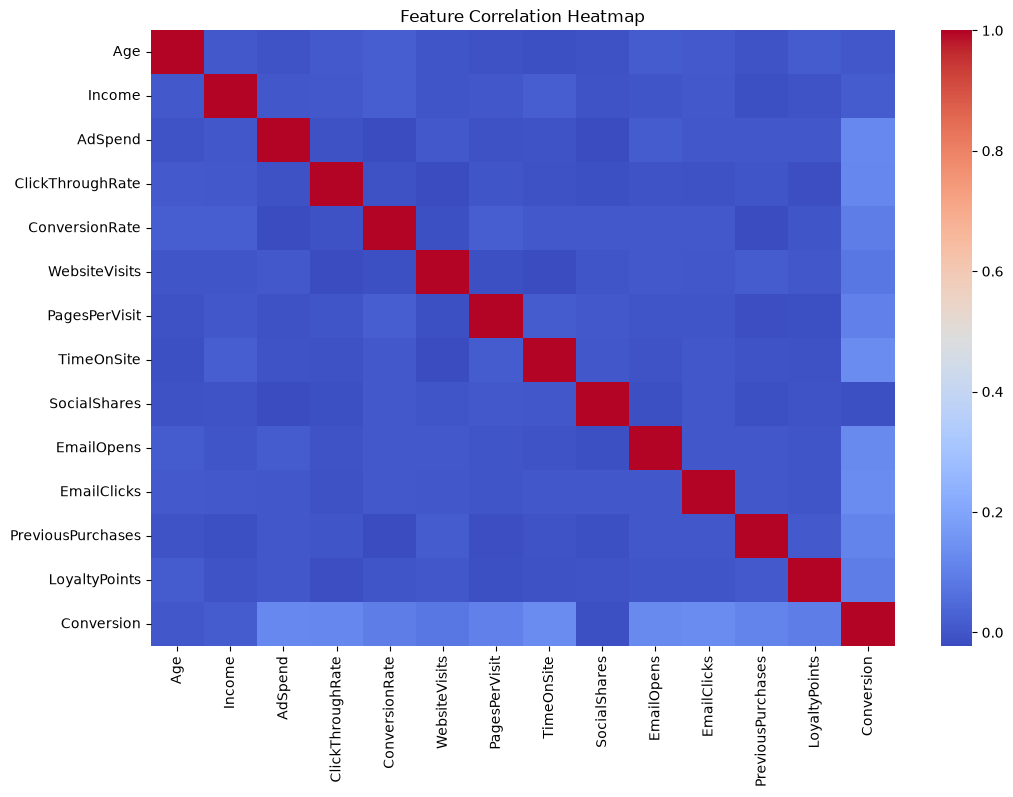

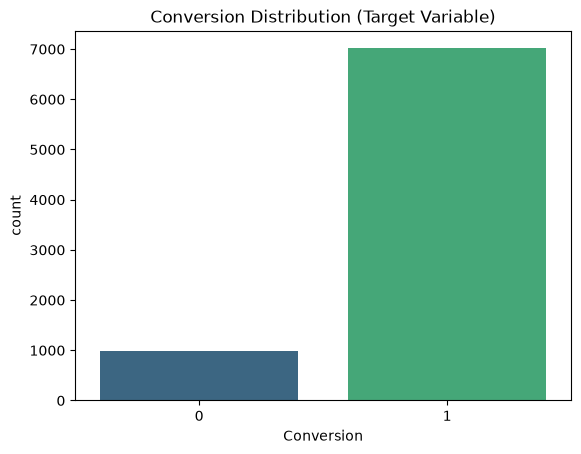

In [3]:

folder_path = r"C:\Users\ASUS\Downloads\digital_marketing_campaign_dataset.csv"
df = pd.read_csv(folder_path)

# Drop irrelevant IDs
drop_cols = ['CustomerID', 'AdvertisingPlatform', 'AdvertisingTool']
df = df.drop(columns=[col for col in drop_cols if col in df.columns], errors='ignore')

print(df.info()) # Fixed execution bug

# EDA: Correlation Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=False, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

# EDA: Target Distribution
sns.countplot(data=df, x='Conversion', palette='viridis')
plt.title("Conversion Distribution (Target Variable)")
plt.show()

# Feature engineering

In [4]:
# Create powerful composite metrics that represent actual marketing behavior.
df['CTOR'] = df['EmailClicks'] / (df['EmailOpens'] + 1e-5)
df['Engagement_Intensity'] = df['PagesPerVisit'] * df['TimeOnSite']
df['Spend_Per_Visit'] = df['AdSpend'] / (df['WebsiteVisits'] + 1)
df['Loyalty_Velocity'] = df['LoyaltyPoints'] / (df['PreviousPurchases'] + 1)

y = df['Conversion'].values
X = df.drop(columns=['Conversion'])

# Strict Train-Test Partitioning (Leakage Prevention)

In [5]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Outlier Handling (Train-Bound)

In [6]:

num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    
    X_train[col] = np.clip(X_train[col], lower, upper)
    X_test[col] = np.clip(X_test[col], lower, upper)

# Iterative VIF Reduction (Train-Bound)

In [7]:

def drop_high_vif(X_tr, X_te, threshold=10.0):
    X_num = X_tr.select_dtypes(include=['int64', 'float64']).copy()
    dropped = []
    while True:
        X_const = add_constant(X_num)
        vif = pd.Series([variance_inflation_factor(X_const.values, i) 
                         for i in range(X_const.shape[1])], index=X_const.columns)
        vif = vif.drop('const')
        if vif.max() > threshold:
            worst_feature = vif.idxmax()
            X_num = X_num.drop(columns=[worst_feature])
            dropped.append(worst_feature)
        else:
            break
    return X_tr.drop(columns=dropped), X_te.drop(columns=dropped)

X_train, X_test = drop_high_vif(X_train, X_test)


In [8]:

X_vif = pd.get_dummies(X_train, drop_first=True, dtype=float)
X_vif = X_vif.replace([np.inf, -np.inf], np.nan).dropna()

X_with_const = add_constant(X_vif)
VIF = pd.DataFrame({
    "VIF Factor": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_with_const.values, i)
        for i in range(1, X_with_const.shape[1]) # Starts at 1 to skip 'const'
    ]
})
VIF = VIF.sort_values(by="VIF", ascending=False).reset_index(drop=True)

print("\nVariance Inflation Factor (VIF) Results")
print(VIF.head(10))
# If any VIF > 10 appears here, you can manually add a line below to drop them.



Variance Inflation Factor (VIF) Results
             VIF Factor       VIF
0  Engagement_Intensity  8.926478
1            TimeOnSite  5.414405
2      Loyalty_Velocity  4.927692
3       Spend_Per_Visit  4.668764
4         PagesPerVisit  4.339287
5                  CTOR  3.908014
6         WebsiteVisits  3.428211
7     PreviousPurchases  3.309958
8            EmailOpens  2.905579
9         LoyaltyPoints  2.625246


# Preprocessing Pipeline & SMOTE

In [9]:

cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        # Added sparse_output=False so we can easily view the matrix
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# Fit entirely on Train, Transform on Test
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)


feature_names = preprocessor.get_feature_names_out()

# PROOF IT WORKED: Convert back to a DataFrame to see the scaling & encoding!

X_train_df = pd.DataFrame(X_train_trans, columns=feature_names)
print(" SCALED & ENCODED TRAINING DATA (First 3 Rows)")
display(X_train_df.head(3))

# Apply SMOTE strictly to the transformed training set
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_trans, y_train)

print(f"\nOriginal Train Target Distribution: {pd.Series(y_train).value_counts().to_dict()}")
print(f"SMOTE Balanced Target Distribution: {pd.Series(y_train_bal).value_counts().to_dict()}")

 SCALED & ENCODED TRAINING DATA (First 3 Rows)


,num__Age,num__Income,num__AdSpend,num__ClickThroughRate,num__ConversionRate,num__WebsiteVisits,num__PagesPerVisit,num__TimeOnSite,num__SocialShares,num__EmailOpens,...,num__Spend_Per_Visit,num__Loyalty_Velocity,cat__Gender_Male,cat__CampaignChannel_PPC,cat__CampaignChannel_Referral,cat__CampaignChannel_SEO,cat__CampaignChannel_Social Media,cat__CampaignType_Consideration,cat__CampaignType_Conversion,cat__CampaignType_Retention
0,-1.187589,1.255559,0.900155,1.582807,0.436789,0.714702,-0.480417,1.100174,-0.268326,1.322327,...,-0.275226,-0.779240,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,0.627801,-0.542982,0.216438,-1.548607,-0.533424,1.065271,1.331265,1.209449,0.668035,-0.598438,...,-0.584673,0.208514,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,0.829511,0.936737,-1.655482,-1.578586,0.954242,1.415841,0.590154,-0.514470,-1.031287,1.147712,...,-1.137768,0.158393,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0



Original Train Target Distribution: {1: 5610, 0: 790}
SMOTE Balanced Target Distribution: {1: 5610, 0: 5610}


In [10]:
# From here, we can proceed to model training and evaluation.
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, 
    AdaBoostClassifier, StackingClassifier
)
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Define the base estimators for the Stacking Classifier
stacking_estimators = [
    ('lr', LogisticRegression(max_iter=1000, random_state=42)),
    ('dt', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42))
]

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Stacking Classifier": StackingClassifier(
        estimators=stacking_estimators,
        final_estimator=LogisticRegression(),
        cv=5
    )
}

summary_results = []
print("\nStarting Training & Evaluation Loop across all 9 models (Single Pass)...")

for name, model in models.items():
    
    model.fit(X_train_bal, y_train_bal)
    
    # Predict on the Test Set
    y_test_pred = model.predict(X_test_trans)
    
    # Predict on the Train Set (to check for overfitting)
    y_train_pred = model.predict(X_train_bal)
    
    #  Handle SVM and others that might not output predict_proba seamlessly
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_trans)[:, 1]
        auc = roc_auc_score(y_test, y_prob)
    else:
        auc = np.nan
        
    # 5. Store all metrics in one go
    summary_results.append({
        "Model": name,
        "Train F1-Score": f1_score(y_train_bal, y_train_pred), 
        "Test F1-Score": f1_score(y_test, y_test_pred),             
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred),
        "ROC-AUC": auc
    })

# 6. Generate the final leaderboard
benchmark_df = pd.DataFrame(summary_results).sort_values(by="Test F1-Score", ascending=False)
print("\n BENCHMARK PERFORMANCE ")
print(benchmark_df.to_string(index=False))


Starting Training & Evaluation Loop across all 9 models (Single Pass)...

 BENCHMARK PERFORMANCE 
              Model  Train F1-Score  Test F1-Score  Accuracy  Precision   Recall  ROC-AUC
  Gradient Boosting        0.951556       0.952644  0.914375   0.924212 0.982882 0.810077
            XGBoost        0.999822       0.951791  0.912500   0.920107 0.985735 0.799857
      Random Forest        1.000000       0.939842  0.890625   0.907100 0.975036 0.791957
Stacking Classifier        1.000000       0.935906  0.883750   0.905333 0.968616 0.789467
           AdaBoost        0.903998       0.926460  0.872500   0.936589 0.916548 0.808221
                SVM        0.921614       0.907636  0.841250   0.925816 0.890157 0.750434
      Decision Tree        0.801888       0.870571  0.783125   0.912432 0.832382 0.687137
Logistic Regression        0.749033       0.844903  0.755625   0.951743 0.759629 0.781881
                KNN        0.867117       0.787485  0.673125   0.915014 0.691155 0.654984



Hyperparameter Tuning for Top 3 Models...
Tuning XGBoost (Tuned)...
Finished XGBoost (Tuned) in 13.13 seconds.
Tuning Gradient Boosting (Tuned)...
Finished Gradient Boosting (Tuned) in 79.33 seconds.
Tuning Random Forest (Tuned)...
Finished Random Forest (Tuned) in 21.60 seconds.

 POST-TUNING PERFORMANCE 
                    Model  Train F1-Score  Test F1-Score  Accuracy  Precision   Recall
          XGBoost (Tuned)        0.996448       0.953624  0.915625   0.919814 0.990014
Gradient Boosting (Tuned)        0.992393       0.953560  0.915625   0.920930 0.988588
    Random Forest (Tuned)        0.976059       0.940728  0.893125   0.915037 0.967903

Extracting Drivers from Top Model: XGBoost (Tuned)


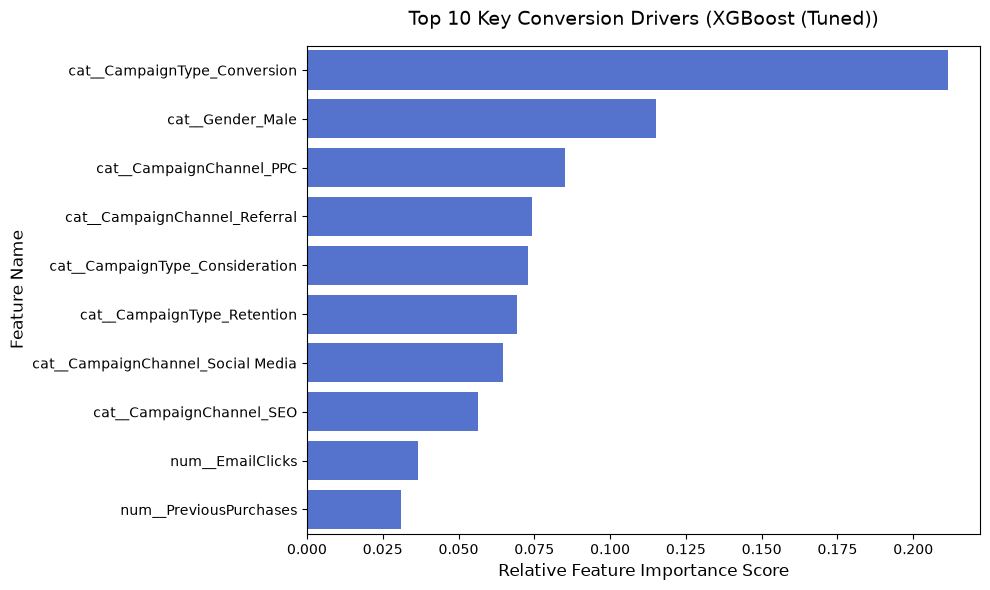

 TOP 10 CONVERSION DRIVERS (XGBOOST (TUNED))
                          Feature  Importance
     cat__CampaignType_Conversion    0.211443
                 cat__Gender_Male    0.115185
         cat__CampaignChannel_PPC    0.085256
    cat__CampaignChannel_Referral    0.074086
  cat__CampaignType_Consideration    0.073022
      cat__CampaignType_Retention    0.069284
cat__CampaignChannel_Social Media    0.064628
         cat__CampaignChannel_SEO    0.056318
                 num__EmailClicks    0.036724
           num__PreviousPurchases    0.031050


In [11]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
import time



# 1. XGBoost (Constrained to prevent SMOTE memorization)
xgb_param_dist = {
    'n_estimators': randint(60, 200),
    'learning_rate': uniform(0.01, 0.15),
    'max_depth': randint(3, 7),
    'subsample': uniform(0.5, 0.5),
    'colsample_bytree': uniform(0.5, 0.5),
    'gamma': uniform(0, 3)
}

# 2. Gradient Boosting
gb_param_dist = {
    'n_estimators': randint(80, 200),
    'learning_rate': uniform(0.01, 0.15),
    'max_depth': randint(3, 7),
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 5)
}

# 3. Random Forest (Constrained depth and increased leaf samples)
rf_param_dist = {
    'n_estimators': randint(100, 250),
    'max_depth': randint(5, 12),
    'min_samples_split': randint(5, 15),
    'min_samples_leaf': randint(2, 10),
    'max_features': ['sqrt', 'log2']
}




searches = {
    "XGBoost (Tuned)": RandomizedSearchCV(
        XGBClassifier(eval_metric='logloss', random_state=42),
        param_distributions=xgb_param_dist, n_iter=20, cv=5, scoring='f1', n_jobs=-1, random_state=42
    ),
    "Gradient Boosting (Tuned)": RandomizedSearchCV(
        GradientBoostingClassifier(random_state=42),
        param_distributions=gb_param_dist, n_iter=20, cv=5, scoring='f1', n_jobs=-1, random_state=42
    ),
    "Random Forest (Tuned)": RandomizedSearchCV(
        RandomForestClassifier(random_state=42),
        param_distributions=rf_param_dist, n_iter=20, cv=5, scoring='f1', n_jobs=-1, random_state=42
    )
}



tuned_results = []
best_overall_model = None
best_overall_f1 = 0
best_model_name = ""

print("\nHyperparameter Tuning for Top 3 Models...")

for name, search in searches.items():
    print(f"Tuning {name}...")
    start_time = time.time()
    
    # Fit the search using the secured SMOTE data
    search.fit(X_train_bal, y_train_bal)
    
    # Extract best model
    best_model = search.best_estimator_
    
    # Predict using the properly scaled arrays
    y_train_pred = best_model.predict(X_train_bal)
    y_test_pred = best_model.predict(X_test_trans)
    
    test_f1 = f1_score(y_test, y_test_pred)
    
    # Track the ultimate best model for feature importance later
    if test_f1 > best_overall_f1:
        best_overall_f1 = test_f1
        best_overall_model = best_model
        best_model_name = name

    tuned_results.append({
        "Model": name,
        "Train F1-Score": f1_score(y_train_bal, y_train_pred),
        "Test F1-Score": test_f1,
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred)
    })
    
    print(f"Finished {name} in {(time.time() - start_time):.2f} seconds.")


# POST-TUNING BENCHMARK
tuned_df = pd.DataFrame(tuned_results).sort_values(by="Test F1-Score", ascending=False)
print("\n POST-TUNING PERFORMANCE ")
print(tuned_df.to_string(index=False))


#  EXTRACT FEATURE IMPORTANCES FROM THE WINNER

print(f"\nExtracting Drivers from Top Model: {best_model_name}")

importance_df = pd.DataFrame({
    'Feature': feature_names, # Mapped correctly to the extracted ColumnTransformer names
    'Importance': best_overall_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Plotting
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), color='royalblue')
plt.title(f'Top 10 Key Conversion Drivers ({best_model_name})', fontsize=14, pad=15)
plt.xlabel('Relative Feature Importance Score', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.tight_layout()
plt.show()


print(f" TOP 10 CONVERSION DRIVERS ({best_model_name.upper()})")

print(importance_df.head(10).to_string(index=False))

In [12]:

# EXPORT MODEL FOR STREAMLIT UI

# Saving the required components for your app.py file
joblib.dump(best_model, 'conversion_model.joblib')
joblib.dump(preprocessor, 'preprocessor.joblib')
joblib.dump(num_cols, 'num_cols.joblib')
joblib.dump(cat_cols, 'cat_cols.joblib')
print("Model, Preprocessor, and Column Lists saved successfully for Streamlit Deployment!")

Model, Preprocessor, and Column Lists saved successfully for Streamlit Deployment!


Default 0.50 Threshold Profit: $278,245.00
Optimal ROAS Cutoff Threshold: 0.40
Projected Maximized Profit: $279,425.00


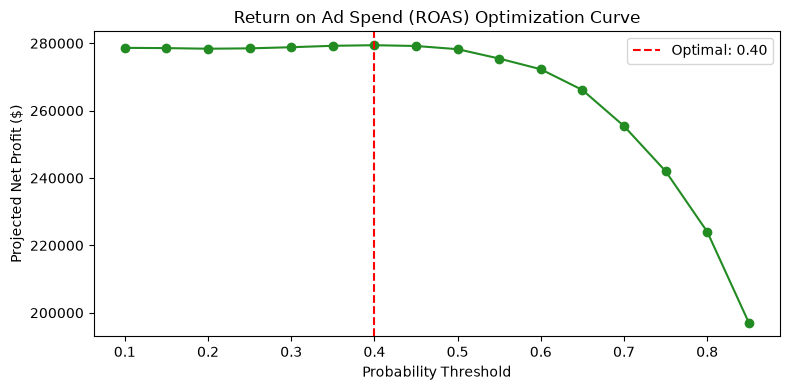

In [13]:

# 8. BUSINESS IMPACT: ROAS OPTIMIZATION THRESHOLD

from xgboost import XGBClassifier
import numpy as np
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt


best_model = XGBClassifier(
    n_estimators=150, 
    max_depth=5, 
    learning_rate=0.05, 
    eval_metric='logloss', 
    random_state=42
)
# Rebuild the balanced training data if earlier notebook cells were not executed
if 'X_train_bal' not in globals() or 'y_train_bal' not in globals():
    if 'X_train' not in globals() or 'y_train' not in globals():
        # Rebuild the split from the original data if the train/test arrays were lost

        if 'X' in globals() and 'y' in globals():
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=0.2, random_state=42, stratify=y
            )
        elif 'df' in globals() and 'Conversion' in df.columns:
            X = df.drop(columns=['Conversion'])
            y = df['Conversion'].values
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=0.2, random_state=42, stratify=y
            )
        else:
            # Fallback: reload the dataset and recreate the engineered features

            data_path = r"C:\Users\ASUS\Downloads\digital_marketing_campaign_dataset.csv"
            df = pd.read_csv(data_path)

            df = df.drop(columns=[col for col in ['CustomerID', 'AdvertisingPlatform', 'AdvertisingTool'] if col in df.columns], errors='ignore')
            df['CTOR'] = df['EmailClicks'] / (df['EmailOpens'] + 1e-5)
            df['Engagement_Intensity'] = df['PagesPerVisit'] * df['TimeOnSite']
            df['Spend_Per_Visit'] = df['AdSpend'] / (df['WebsiteVisits'] + 1)
            df['Loyalty_Velocity'] = df['LoyaltyPoints'] / (df['PreviousPurchases'] + 1)

            X = df.drop(columns=['Conversion'])
            y = df['Conversion'].values
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=0.2, random_state=42, stratify=y
            )

        if 'X_train' not in globals() or 'y_train' not in globals():
            raise NameError("Missing X_train/y_train. Run the train-test split first.")
    
    if 'preprocessor' in globals():
        if 'X_train_trans' not in globals():
            X_train_trans = preprocessor.fit_transform(X_train)
        if 'X_test_trans' not in globals():
            X_test_trans = preprocessor.transform(X_test)
    elif 'X_train_trans' not in globals():
        raise NameError("Missing preprocessing objects and transformed data. Run preprocessing first.")
    
    smote = SMOTE(random_state=42)
    X_train_bal, y_train_bal = smote.fit_resample(X_train_trans, y_train)

best_model.fit(X_train_bal, y_train_bal)

# 1. Generate the probabilities directly from the freshly trained model
y_test_prob = best_model.predict_proba(X_test_trans)[:, 1]

# 2. Instead of a default 0.50 cutoff, we calculate the threshold that maximizes profit.
AOV = 250  # Average Order Value for a conversion ($)
CAC = 45   # Cost of marketing intervention per predicted customer ($)

thresholds = np.arange(0.1, 0.9, 0.05)
profits = []

for t in thresholds:
    custom_preds = (y_test_prob >= t).astype(int)
    # True Positives (Revenue generated)
    tp = np.sum((custom_preds == 1) & (y_test == 1))
    # False Positives (Marketing money wasted on non-converters)
    fp = np.sum((custom_preds == 1) & (y_test == 0))
    
    net_profit = (tp * (AOV - CAC)) - (fp * CAC)
    profits.append(net_profit)

optimal_threshold = thresholds[np.argmax(profits)]
max_profit = max(profits)

# Get the standard 0.50 cutoff predictions for baseline comparison
y_test_pred = best_model.predict(X_test_trans)

print(f"Default 0.50 Threshold Profit: ${(np.sum((y_test_pred==1)&(y_test==1))*(AOV-CAC)) - (np.sum((y_test_pred==1)&(y_test==0))*CAC):,.2f}")
print(f"Optimal ROAS Cutoff Threshold: {optimal_threshold:.2f}")
print(f"Projected Maximized Profit: ${max_profit:,.2f}")

# Plot the profit curve
plt.figure(figsize=(8, 4))
plt.plot(thresholds, profits, marker='o', color='forestgreen')
plt.axvline(optimal_threshold, color='red', linestyle='--', label=f'Optimal: {optimal_threshold:.2f}')
plt.title("Return on Ad Spend (ROAS) Optimization Curve")
plt.xlabel("Probability Threshold")
plt.ylabel("Projected Net Profit ($)")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
import joblib

# Bundle preprocessor and best XGBoost model
model_artifact = {
    'preprocessor': preprocessor,  # Your ColumnTransformer/pipeline
    'model': best_overall_model     # XGBoost (Tuned)
}

# Save artifact
joblib.dump(model_artifact, 'marketing_conversion_model.joblib')
print("Model artifact successfully saved as 'marketing_conversion_model.joblib'")

Model artifact successfully saved as 'marketing_conversion_model.joblib'


Generating Advanced EDA Visualizations...


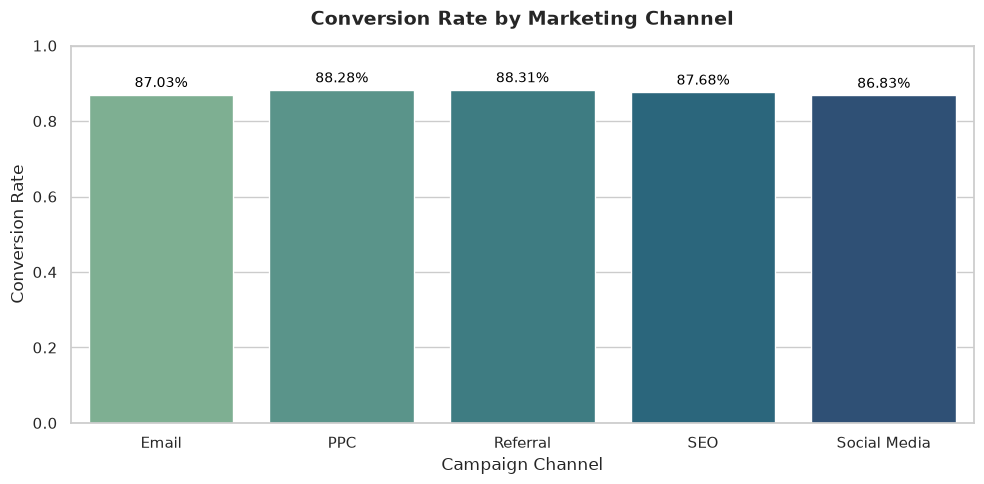

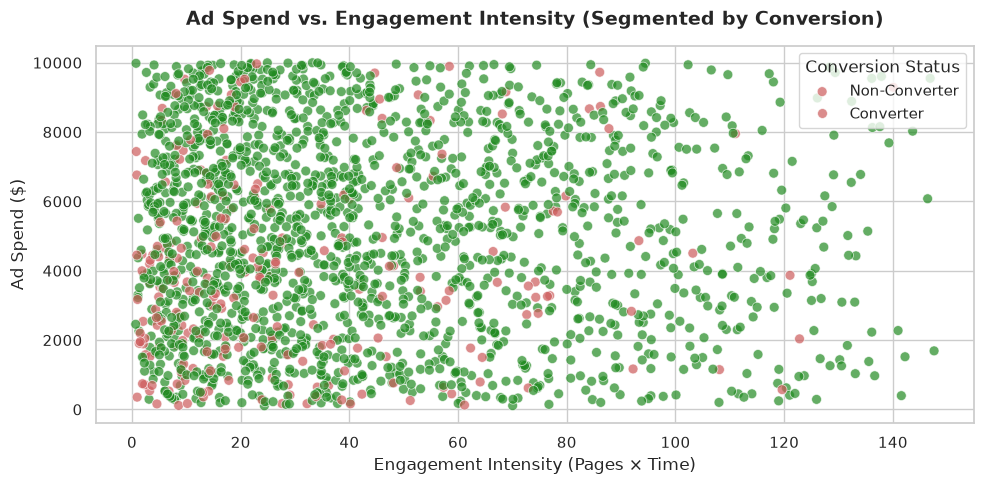

Advanced EDA generation complete!


In [15]:

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import numpy as np
import pandas as pd

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("Generating Advanced EDA Visualizations...")



# Figure 1: Campaign Channel Performance vs Conversion Rate
plt.figure(figsize=(10, 5))
channel_conv = df.groupby('CampaignChannel')['Conversion'].mean().reset_index()
ax = sns.barplot(data=channel_conv, x='CampaignChannel', y='Conversion', palette='crest')
plt.title("Conversion Rate by Marketing Channel", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Campaign Channel", fontsize=12)
plt.ylabel("Conversion Rate", fontsize=12)
plt.ylim(0, 1.0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2%}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()

# Figure 2: Engagement Intensity vs Ad Spend (Faceted by Conversion)
plt.figure(figsize=(10, 5))
# Create temporary engagement metric if not already present
if 'Engagement_Intensity' not in df.columns:
    df['Engagement_Intensity'] = df['PagesPerVisit'] * df['TimeOnSite']

sns.scatterplot(
    data=df.sample(min(2000, len(df)), random_state=42), 
    x='Engagement_Intensity', y='AdSpend', 
    hue='Conversion', palette={0: 'indianred', 1: 'forestgreen'}, 
    alpha=0.7, s=50
)
plt.title("Ad Spend vs. Engagement Intensity (Segmented by Conversion)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Engagement Intensity (Pages × Time)", fontsize=12)
plt.ylabel("Ad Spend ($)", fontsize=12)
plt.legend(title="Conversion Status", labels=['Non-Converter', 'Converter'])
plt.tight_layout()
plt.show()




# Interactive Chart 1: Sunburst Chart of Campaign Type & Channel Breakdown
fig_sunburst = px.sunburst(
    df, 
    path=['CampaignType', 'CampaignChannel', 'Conversion'], 
    title="<b>Interactive Hierarchy: Campaign Type → Channel → Conversion</b>",
    color_discrete_sequence=px.colors.qualitative.Prism
)
fig_sunburst.update_layout(width=700, height=700)
fig_sunburst.show()

# Interactive Chart 2: 3D Scatter Plot of Key Numerical Drivers
fig_3d = px.scatter_3d(
    df.sample(min(1500, len(df)), random_state=42),
    x='AdSpend',
    y='Engagement_Intensity',
    z='LoyaltyPoints',
    color='Conversion',
    color_continuous_scale='Viridis',
    title="<b>3D Behavioral Cluster Analysis (Spend vs Engagement vs Loyalty)</b>",
    opacity=0.7
)
fig_3d.update_layout(width=800, height=600)
fig_3d.show()

print("Advanced EDA generation complete!")

In [16]:

import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
import numpy as np

# Ensure engagement intensity exists
if 'Engagement_Intensity' not in df.columns:
    df['Engagement_Intensity'] = df['PagesPerVisit'] * df['TimeOnSite']

# 1. Single Cost vs. Engagement Matrix (Bubble Scatter with Color Scale)
fig_matrix = px.scatter(
    df.sample(min(2000, len(df)), random_state=42),
    x='AdSpend',
    y='Engagement_Intensity',
    color='Conversion',
    size='WebsiteVisits',
    color_continuous_scale='plasma',
    title="<b>Cost vs. Engagement Matrix</b>",
    labels={'AdSpend': 'Ad Spend ($)', 'Engagement_Intensity': 'Engagement Intensity (Pages x Time)'},
    opacity=0.8
)
fig_matrix.update_layout(
    template='plotly_white',
    title_font_size=16,
    width=900, height=500
)
fig_matrix.show()

# 2. Faceted Matrix by Campaign Type (4-Panel Grid)
fig_faceted = px.scatter(
    df.sample(min(3000, len(df)), random_state=42),
    x='AdSpend',
    y='Engagement_Intensity',
    color='Conversion',
    size='WebsiteVisits',
    facet_col='CampaignType',
    facet_col_wrap=2,
    color_continuous_scale='plasma',
    title="<b>Cost vs. Engagement Matrix by Campaign Type</b>",
    opacity=0.8
)
fig_faceted.update_layout(
    template='plotly_white',
    title_font_size=16,
    width=900, height=700
)
fig_faceted.show()

# 3. Campaign Efficiency Treemap (Size = Volume, Color = Conversion Rate)
# Aggregate data for the treemap hierarchy
treemap_df = df.groupby(['CampaignChannel', 'CampaignType']).agg(
    Conversion_Rate=('Conversion', 'mean'),
    Total_Volume=('Conversion', 'count')
).reset_index()

fig_treemap = px.treemap(
    treemap_df,
    path=['CampaignChannel', 'CampaignType'],
    values='Total_Volume',
    color='Conversion_Rate',
    color_continuous_scale='RdYlGn',
    title="<b>Campaign Efficiency Hierarchy (Size = Volume, Color = Conversion Rate)</b>"
)
fig_treemap.update_layout(
    template='plotly_white',
    title_font_size=16,
    width=950, height=600
)
fig_treemap.show()

In [ ]:
import joblib

# Export model artifacts
artifacts = {
    "preprocessor": preprocessor, # Replace with your preprocessor variable name if different
    "model": models["XGBoost"],   # Replace with your trained model variable name
    "feature_names": X_train.columns.tolist() # Replace with your X_train variable name
}

joblib.dump(artifacts, "marketing_conversion_pipeline.joblib")
print("Pipeline artifacts successfully saved!")

Pipeline artifacts successfully saved to 'marketing_conversion_pipeline.joblib'
